In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline

In [171]:
df = pd.read_excel("Telco_customer_churn.xlsx")

In [172]:
pd.set_option('display.max_columns',None)

In [173]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [174]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

The column of total charges has a object datatype but it should be numerical

In [175]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"],errors="coerce")

In [176]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges          11
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [177]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,2283.300441,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,2266.771362,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,18.800000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,401.450000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,1397.475000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,3794.737500,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,8684.800000,1.000000,100.000000,6500.000000


In [178]:
df['Total Charges'] = df['Total Charges'].fillna( df['Monthly Charges'] * df['Tenure Months'] )


In [179]:
Churn_Label_counts = df['Churn Label'].value_counts()
print(Churn_Label_counts)
fig = px.pie(names= Churn_Label_counts.keys(), values= Churn_Label_counts.values, title='Churn Label Distribution')
fig.show()


Churn Label
No     5174
Yes    1869
Name: count, dtype: int64


From above pie chart we get to know that 26.5% customers have stopped using our services.

In [180]:
values= df['Churn Reason'].value_counts(ascending=False).values
keys= df['Churn Reason'].value_counts(ascending=False).keys()

fig = px.bar(x=keys, y=values, color = values, text = values)

fig.update_layout(
    yaxis_title="Churn Reason",
    xaxis_title="Count"
)
fig.show()

Tells us the reason of churn ie. why the customer left

In [181]:
fig = px.histogram(df,marginal="box",x="Tenure Months",color="Churn Label")
fig.update_layout(bargap = 0.1)
fig.show()

Churned customers usually have lower tenure
ie. As tenure increases → churn decreasess

In [182]:
fig = px.histogram(df,marginal="box",x="Total Charges",color="Churn Label")
fig.update_layout(bargap = 0.1)
fig.show()

In [183]:
Contract_Label_counts= df['Contract'].value_counts()
fig = px.pie(names= Contract_Label_counts.keys(), values= Contract_Label_counts.values, title='Contract Distribution')
fig.show()

In [184]:
fig = px.histogram(
    df,
    x="Contract",
    color="Churn Label",
    barmode="stack",
    title="Contract vs Churn"
)

fig.show()


In [185]:
fig = px.box(
    df,
    x="Churn Label",
    y="Monthly Charges",
    title="Monthly Charges vs Churn"
)

fig.show()


In [186]:
fig = px.scatter(
    df,
    x="Tenure Months",
    y="Total Charges",
    trendline="ols",
    trendline_color_override="red",
    title="Tenure Months vs Total Charges"
)

fig.show()


As Tenure Months increase, Total Charges increase

The red OLS line confirms a strong positive linear relationship

In [187]:
df[['Tenure Months', 'Total Charges']].corr()

,Tenure Months,Total Charges
Tenure Months,1.000000,0.826178
Total Charges,0.826178,1.000000


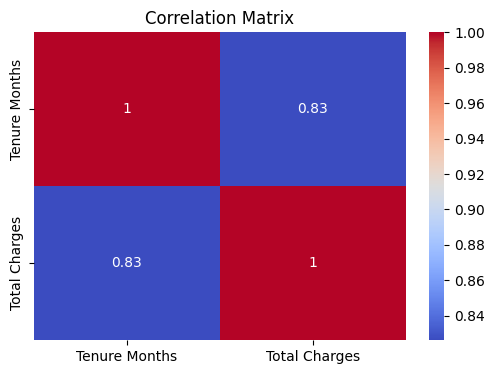

In [188]:
plt.figure(figsize=(6,4))
sns.heatmap(
    df[['Tenure Months', 'Total Charges']].corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title("Correlation Matrix")
plt.show()

“The correlation matrix shows a strong positive correlation between Tenure Months and Total Charges, indicating that as customer tenure increases, the total charges increase in a nearly linear manner.”

In [189]:
fig = px.scatter(
    df,
    x="Tenure Months",
    y="CLTV",
    trendline="ols",
    trendline_color_override="red",
    title="Tenure Months vs CLTV"
)

fig.show()


In [190]:
df[['Tenure Months', 'CLTV']].corr()

,Tenure Months,CLTV
Tenure Months,1.000000,0.396406
CLTV,0.396406,1.000000


In [234]:
# encode target 
df["Churn Label"] = df["Churn Label"].map({"Yes":1,"No":0})


In [192]:
df.drop(columns=['CustomerID','Count','Country','State','City','Zip Code','Lat Long',
    'Latitude','Longitude','Churn Reason','Churn Value','Churn Score'],inplace=True)  # Dropping Columns which are not relevant to O/P

In [193]:
# Convert binary Yes/No columns to 1/0
binary_cols = ['Senior Citizen','Partner','Dependents','Phone Service','Multiple Lines',
               'Online Security','Online Backup','Device Protection','Tech Support',
               'Streaming TV','Streaming Movies','Paperless Billing']

In [194]:
for col in binary_cols:
    df[col] = df[col].map({"Yes":1,"No":0})

In [195]:
df.nunique()

Gender                  2
Senior Citizen          2
Partner                 2
Dependents              2
Tenure Months          73
Phone Service           2
Multiple Lines          2
Internet Service        3
Online Security         2
Online Backup           2
Device Protection       2
Tech Support            2
Streaming TV            2
Streaming Movies        2
Contract                3
Paperless Billing       2
Payment Method          4
Monthly Charges      1585
Total Charges        6531
Churn Label             2
CLTV                 3438
dtype: int64

In [196]:
# One-hot encode nominal categorical columns
nominal_cols = ['Gender','Internet Service','Contract','Payment Method']
df = pd.get_dummies(df, columns=nominal_cols, drop_first=True)

In [197]:
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)


In [198]:
df.fillna(0, inplace=True)

In [199]:
X = df.drop('Churn Label', axis=1)
X_const = X.copy()

vif_data = pd.DataFrame()
vif_data["Feature"] = X_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i)
                   for i in range(X_const.shape[1])]

vif_data.sort_values(by="VIF", ascending=False)

,Feature,VIF
13,Monthly Charges,302.918662
4,Phone Service,53.095653
17,Internet Service_Fiber optic,22.724122
14,Total Charges,21.319411
3,Tenure Months,20.652191
15,CLTV,17.291255
18,Internet Service_No,10.736592
11,Streaming Movies,5.767078
10,Streaming TV,5.647675
20,Contract_Two year,3.454247


In [200]:
df.drop(columns=['Monthly Charges', 'Total Charges', 'Phone Service'], inplace=True)


In [201]:
X = df.drop('Churn Label', axis=1)

vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                   for i in range(X.shape[1])]

vif_data.sort_values(by="VIF", ascending=False)

,Feature,VIF
12,CLTV,9.741967
3,Tenure Months,8.086204
17,Contract_Two year,3.425241
14,Internet Service_Fiber optic,2.989133
15,Internet Service_No,2.830865
11,Paperless Billing,2.806492
10,Streaming Movies,2.663741
9,Streaming TV,2.637189
1,Partner,2.577784
19,Payment Method_Electronic check,2.540753


In [202]:
X = df.drop('Churn Label', axis=1)
y = df['Churn Label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [203]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [204]:
df.head()

,Senior Citizen,Partner,Dependents,Tenure Months,Multiple Lines,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Paperless Billing,Churn Label,CLTV,Gender_Male,Internet Service_Fiber optic,Internet Service_No,Contract_One year,Contract_Two year,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,0,0,0,2,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1,1,3239,1,0,0,0,0,0,0,1
1,0,0,1,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1,2701,0,1,0,0,0,0,1,0
2,0,0,1,8,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1,1,5372,0,1,0,0,0,0,1,0
3,0,1,1,28,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1,1,5003,0,1,0,0,0,0,1,0
4,0,0,1,49,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1,1,5340,1,1,0,0,0,0,0,0


              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.52      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



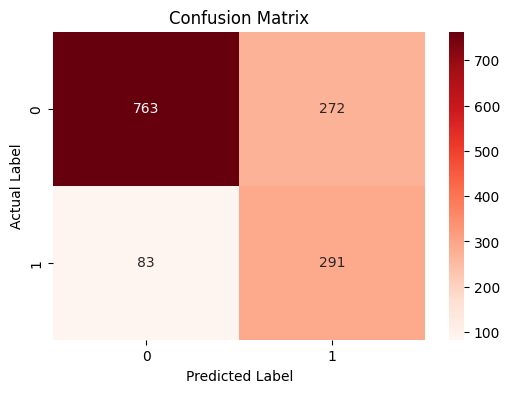

In [ ]:
model = LogisticRegression(max_iter=1000,class_weight="balanced")
model.fit(X_train_scaled, y_train)


y_pred = model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Reds")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()


              precision    recall  f1-score   support

           0       0.88      0.82      0.85      1035
           1       0.58      0.70      0.63       374

    accuracy                           0.78      1409
   macro avg       0.73      0.76      0.74      1409
weighted avg       0.80      0.78      0.79      1409



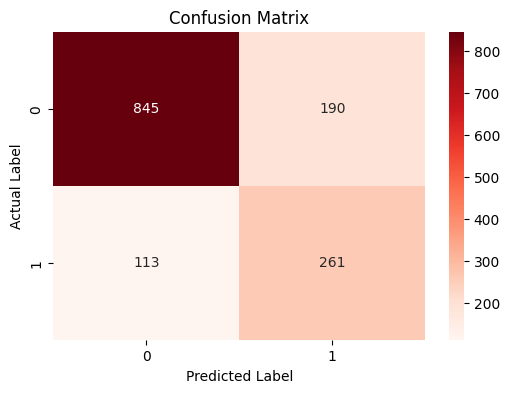

In [ ]:
model = RandomForestClassifier(n_estimators=150,
                               criterion="gini",
                               random_state=42,
                               max_depth=11,
                               class_weight="balanced",)


model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Reds")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()


              precision    recall  f1-score   support

           0       0.85      0.88      0.86      1035
           1       0.63      0.59      0.61       374

    accuracy                           0.80      1409
   macro avg       0.74      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



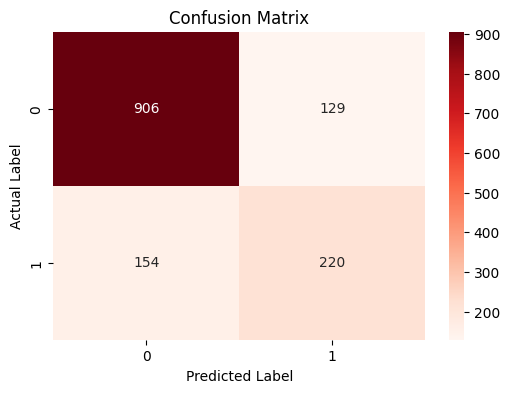

In [ ]:
model = DecisionTreeClassifier(min_samples_leaf=175,
                               criterion="gini",
                               random_state=42,
                               max_depth=11)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Reds")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()
